# YOLO11 on nuScenes — Camera Baseline & Robustness Checkpoint

**Goal:** Verify pretrained YOLO11s inference on nuScenes CAM_FRONT imagery, then compare clean images against controlled darkness and Gaussian blur. This notebook saves per-image predictions, latency summaries, and example visualizations for the team.

**Environment:** Google Colab (GPU recommended). **Dataset:** nuScenes v1.0-mini. **Weights:** COCO-pretrained `yolo11s.pt`.

> The corruption experiment is a smoke test, **not** a ground-truth accuracy evaluation. Precision, recall and mAP require the shared 2D scorer. ROS 2 transport latency is not measured here.

## 1. Environment and project paths

In [ ]:
!pip -q install nuscenes-devkit ultralytics

In [ ]:
%pip install --no-cache-dir --force-reinstall "numpy==2.2.6" "scipy==1.15.3" "scikit-learn==1.6.1"

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

PROJECT_DIR = "/content/drive/MyDrive/ColabNotebooks/CMPE249_PROJ"
NUSCENES_DIR = os.path.join(PROJECT_DIR, "data/nuscenes")
YOLO_RESULTS_DIR = os.path.join(PROJECT_DIR, "results/yolo11")
CHECKPOINT_DIR = os.path.join(YOLO_RESULTS_DIR, "checkpoint_v1")

for folder in [NUSCENES_DIR, YOLO_RESULTS_DIR, CHECKPOINT_DIR]:
    os.makedirs(folder, exist_ok=True)

print("Project:", PROJECT_DIR)
print("Dataset:", NUSCENES_DIR)
print("Checkpoint outputs:", CHECKPOINT_DIR)

Project: /content/drive/MyDrive/ColabNotebooks/CMPE249_PROJ
Dataset: /content/drive/MyDrive/ColabNotebooks/CMPE249_PROJ/data/nuscenes
Checkpoint outputs: /content/drive/MyDrive/ColabNotebooks/CMPE249_PROJ/results/yolo11/checkpoint_v1


In [3]:
!nvidia-smi

Mon Nov  2 06:34:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   30C    P0             47W /  600W |       0MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## 2. Load and inspect nuScenes

The archive only needs extraction **once**. This notebook checks the extracted files first and avoids repeating the extraction on subsequent runs.

In [4]:
import os
archive = os.path.join(NUSCENES_DIR, "v1.0-mini.tgz")
metadata = os.path.join(NUSCENES_DIR, "v1.0-mini")
if not os.path.isdir(metadata):
    if not os.path.isfile(archive):
        raise FileNotFoundError(f"Missing nuScenes archive and extracted metadata in {NUSCENES_DIR}")
    import tarfile
    print("Extracting nuScenes mini archive (first run only)...")
    with tarfile.open(archive, "r:gz") as tar:
        tar.extractall(NUSCENES_DIR, filter="data")
else:
    print("nuScenes metadata already extracted; skipping extraction.")

required = ["maps", "samples/CAM_FRONT", "samples/LIDAR_TOP", "v1.0-mini"]
missing = [p for p in required if not os.path.exists(os.path.join(NUSCENES_DIR, p))]
if missing:
    raise FileNotFoundError(f"Missing extracted nuScenes paths: {missing}")
print("Required nuScenes paths verified.")

nuScenes metadata already extracted; skipping extraction.
Required nuScenes paths verified.


In [5]:
from nuscenes.nuscenes import NuScenes

nusc = NuScenes(
    version="v1.0-mini",
    dataroot=NUSCENES_DIR,
    verbose=True
)

print("\nNumber of scenes:", len(nusc.scene))
print("Number of samples:", len(nusc.sample))

Loading NuScenes tables for version v1.0-mini...
23 category,
8 attribute,
4 visibility,
911 instance,
12 sensor,
120 calibrated_sensor,
31206 ego_pose,
8 log,
10 scene,
404 sample,
31206 sample_data,
18538 sample_annotation,
4 map,
Done loading in 8.892 seconds.
Reverse indexing ...
Done reverse indexing in 0.0 seconds.

Number of scenes: 10
Number of samples: 404


In [6]:
sample = nusc.sample[0]

print("Sample token:", sample["token"])
print("\nAvailable sensors:")

for sensor in sample["data"]:
    print(" -", sensor)

Sample token: ca9a282c9e77460f8360f564131a8af5

Available sensors:
 - RADAR_FRONT
 - RADAR_FRONT_LEFT
 - RADAR_FRONT_RIGHT
 - RADAR_BACK_LEFT
 - RADAR_BACK_RIGHT
 - LIDAR_TOP
 - CAM_FRONT
 - CAM_FRONT_RIGHT
 - CAM_BACK_RIGHT
 - CAM_BACK
 - CAM_BACK_LEFT
 - CAM_FRONT_LEFT


### 2.1 Inspect example camera and LiDAR data

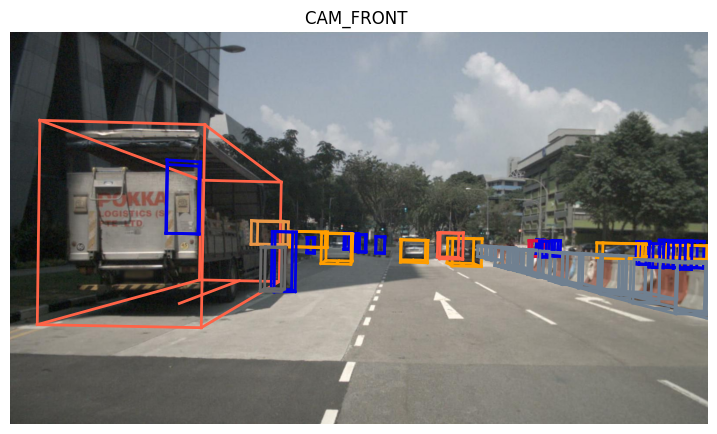

In [7]:
cam_token = sample["data"]["CAM_FRONT"]

nusc.render_sample_data(
    cam_token,
    with_anns=True
)

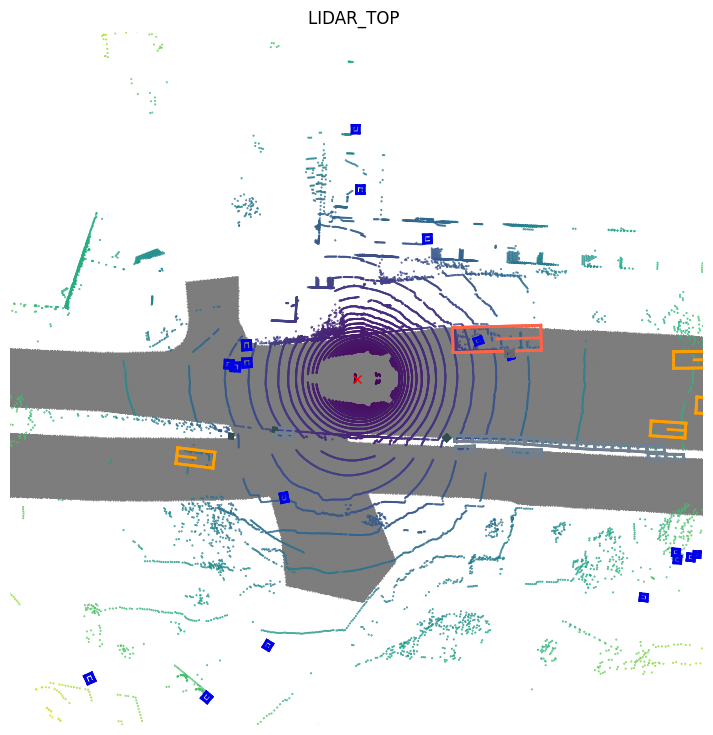

In [8]:
lidar_token = sample["data"]["LIDAR_TOP"]

nusc.render_sample_data(
    lidar_token,
    with_anns=True
)

## 3. YOLO11s — single-image smoke test

In [9]:
from ultralytics import YOLO
import ultralytics
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Ultralytics:", ultralytics.__version__)
model = YOLO("yolo11s.pt")
print("Model: YOLO11s (COCO pretrained)")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.198
Model: YOLO11s (COCO pretrained)


In [10]:
sample = nusc.sample[0]

cam_token = sample["data"]["CAM_FRONT"]
cam_data = nusc.get("sample_data", cam_token)

image_path = f"{NUSCENES_DIR}/{cam_data['filename']}"

print("Image:", image_path)

Image: /content/drive/MyDrive/ColabNotebooks/CMPE249_PROJ/data/nuscenes/samples/CAM_FRONT/n015-2018-07-24-11-22-45+0800__CAM_FRONT__1532402927612460.jpg


In [11]:
import os

print("Exists:", os.path.exists(image_path))

Exists: True


In [12]:
results = model.predict(
    source=image_path,
    conf=0.25,
    verbose=True
)

result = results[0]


image 1/1 /content/drive/MyDrive/ColabNotebooks/CMPE249_PROJ/data/nuscenes/samples/CAM_FRONT/n015-2018-07-24-11-22-45+0800__CAM_FRONT__1532402927612460.jpg: 384x640 4 cars, 2 trucks, 3.6ms
Speed: 58.9ms preprocess, 3.6ms inference, 25.7ms postprocess per image at shape (1, 3, 384, 640)


In [13]:
print("Number of detections:", len(result.boxes))

for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])
    xyxy = box.xyxy[0].tolist()

    print(
        model.names[class_id],
        f"confidence={confidence:.3f}",
        f"box={xyxy}"
    )

Number of detections: 6
truck confidence=0.919 box=[123.22074890136719, 222.21458435058594, 605.326904296875, 625.8394775390625]
car confidence=0.689 box=[1003.8455200195312, 475.8492431640625, 1077.606689453125, 535.910400390625]
car confidence=0.648 box=[896.6156005859375, 482.11578369140625, 957.0071411132812, 528.2266235351562]
car confidence=0.568 box=[716.7618408203125, 461.39898681640625, 785.3206787109375, 530.484375]
car confidence=0.360 box=[1362.93359375, 486.2509765625, 1422.543701171875, 515.6188354492188]
truck confidence=0.275 box=[716.578125, 461.27490234375, 785.27490234375, 531.4142456054688]


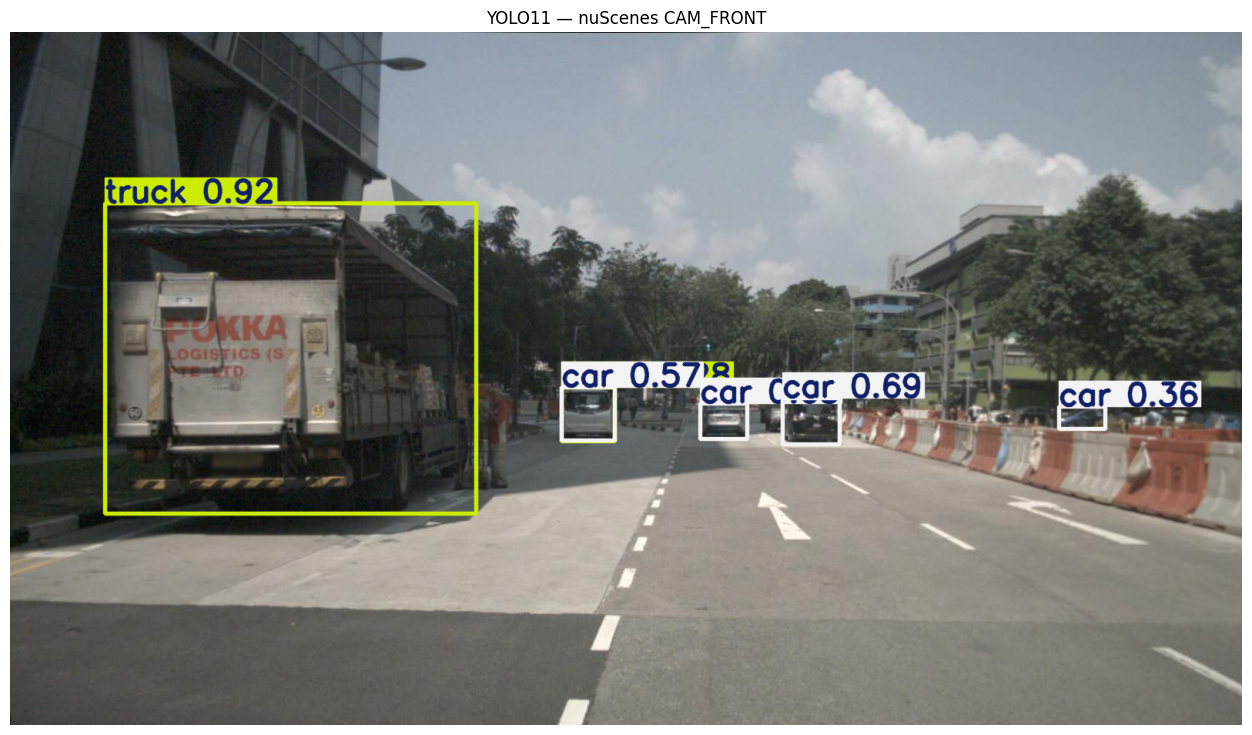

In [14]:
import matplotlib.pyplot as plt

annotated = result.plot()

plt.figure(figsize=(16, 9))
plt.imshow(annotated[..., ::-1])
plt.axis("off")
plt.title("YOLO11 — nuScenes CAM_FRONT")
plt.show()

In [15]:
import cv2
import os

YOLO_RESULTS_DIR = os.path.join(PROJECT_DIR, "results/yolo11")
os.makedirs(YOLO_RESULTS_DIR, exist_ok=True)

output_path = os.path.join(
    YOLO_RESULTS_DIR,
    "nuscenes_cam_front_yolo11.jpg"
)

cv2.imwrite(output_path, annotated)

print("Saved to:")
print(output_path)

Saved to:
/content/drive/MyDrive/ColabNotebooks/CMPE249_PROJ/results/yolo11/nuscenes_cam_front_yolo11.jpg


## 4. Controlled camera-corruption experiment

**Protocol:** Use the same 20 nuScenes CAM_FRONT keyframes under three conditions: `clean`, `dark` (40% brightness), and `blur` (11×11 Gaussian kernel, σ=3). The same pretrained model and confidence threshold are used for all conditions.

**Outputs:** per-detection CSV, per-image CSV (including zero-detection images), latency summary CSV, and side-by-side example figures. These are **not** RoboBEV benchmark-equivalent settings; they are an initial controlled experiment inspired by camera-corruption stress tests.

In [16]:
import csv
import time
import torch
import pandas as pd
from collections import defaultdict

NUM_SAMPLES = 20
CONF_THRESHOLD = 0.25
CONDITIONS = ("clean", "dark", "blur")

# Fixed, reproducible subset; use sample tokens to align with teammates.
samples = nusc.sample[:NUM_SAMPLES]
assert samples, "No nuScenes samples loaded"
print("Samples:", len(samples), "| Conditions:", CONDITIONS)
print("First sample token:", samples[0]["token"])

def corrupt_image(image_bgr, condition):
    if condition == "clean":
        return image_bgr.copy()
    if condition == "dark":
        return np.clip(image_bgr.astype(np.float32) * 0.4, 0, 255).astype(np.uint8)
    if condition == "blur":
        return cv2.GaussianBlur(image_bgr, (11, 11), sigmaX=3)
    raise ValueError(f"Unknown condition: {condition}")

def camera_image_path(sample):
    data = nusc.get("sample_data", sample["data"]["CAM_FRONT"])
    return os.path.join(NUSCENES_DIR, data["filename"])


Samples: 20 | Conditions: ('clean', 'dark', 'blur')
First sample token: ca9a282c9e77460f8360f564131a8af5


### 4.1 Run inference and export predictions

We synchronize CUDA around the inference call for more meaningful wall-clock timings. This excludes disk I/O, corruption generation, and ROS 2 transport. The first image is used for model warm-up.

In [17]:
prediction_rows = []
image_rows = []
example_images = {}

first_image = cv2.imread(camera_image_path(samples[0]))
if first_image is None:
    raise FileNotFoundError(camera_image_path(samples[0]))

for _ in range(3):
    model.predict(first_image, conf=CONF_THRESHOLD, verbose=False)
if torch.cuda.is_available():
    torch.cuda.synchronize()

for sample_index, sample in enumerate(samples):
    image_path = camera_image_path(sample)
    image = cv2.imread(image_path)
    if image is None:
        raise FileNotFoundError(image_path)

    for condition in CONDITIONS:
        modified = corrupt_image(image, condition)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        start = time.perf_counter()
        result = model.predict(modified, conf=CONF_THRESHOLD, verbose=False)[0]
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        elapsed_ms = (time.perf_counter() - start) * 1000

        image_rows.append({
            "sample_token": sample["token"],
            "camera": "CAM_FRONT",
            "condition": condition,
            "num_detections": len(result.boxes),
            "latency_ms": elapsed_ms,
            "image_width": image.shape[1],
            "image_height": image.shape[0],
        })
        for box in result.boxes:
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            prediction_rows.append({
                "sample_token": sample["token"],
                "camera": "CAM_FRONT",
                "condition": condition,
                "class_id_coco": int(box.cls[0]),
                "class_name_coco": model.names[int(box.cls[0])],
                "confidence": float(box.conf[0]),
                "x1": x1, "y1": y1, "x2": x2, "y2": y2,
            })
        if sample_index == 0:
            example_images[condition] = result.plot()

pred_df = pd.DataFrame(prediction_rows, columns=[
    "sample_token", "camera", "condition", "class_id_coco", "class_name_coco",
    "confidence", "x1", "y1", "x2", "y2"
])
image_df = pd.DataFrame(image_rows)
pred_path = os.path.join(CHECKPOINT_DIR, "predictions.csv")
image_path_csv = os.path.join(CHECKPOINT_DIR, "per_image_results.csv")
pred_df.to_csv(pred_path, index=False)
image_df.to_csv(image_path_csv, index=False)
print(f"Saved {len(pred_df)} detections -> {pred_path}")
print(f"Saved {len(image_df)} image-condition results -> {image_path_csv}")

Saved 579 detections -> /content/drive/MyDrive/ColabNotebooks/CMPE249_PROJ/results/yolo11/checkpoint_v1/predictions.csv
Saved 60 image-condition results -> /content/drive/MyDrive/ColabNotebooks/CMPE249_PROJ/results/yolo11/checkpoint_v1/per_image_results.csv


### 4.2 Summarize latency and detection counts

In [18]:
summary_df = (image_df.groupby("condition", sort=False)
              .agg(images=("sample_token", "count"),
                   total_detections=("num_detections", "sum"),
                   mean_detections_per_image=("num_detections", "mean"),
                   mean_latency_ms=("latency_ms", "mean"),
                   median_latency_ms=("latency_ms", "median"))
              .reset_index())
summary_path = os.path.join(CHECKPOINT_DIR, "condition_summary.csv")
summary_df.to_csv(summary_path, index=False)
display(summary_df.round(2))
print("Saved:", summary_path)
print("Note: detection counts are NOT accuracy metrics; ground-truth matching is still needed.")

,condition,images,total_detections,mean_detections_per_image,mean_latency_ms,median_latency_ms
0,clean,20,207,10.35,4.74,4.79
1,dark,20,206,10.30,5.07,5.07
2,blur,20,166,8.30,4.06,4.06


Saved: /content/drive/MyDrive/ColabNotebooks/CMPE249_PROJ/results/yolo11/checkpoint_v1/condition_summary.csv
Note: detection counts are NOT accuracy metrics; ground-truth matching is still needed.


### 4.3 Visualize a matched failure-case example

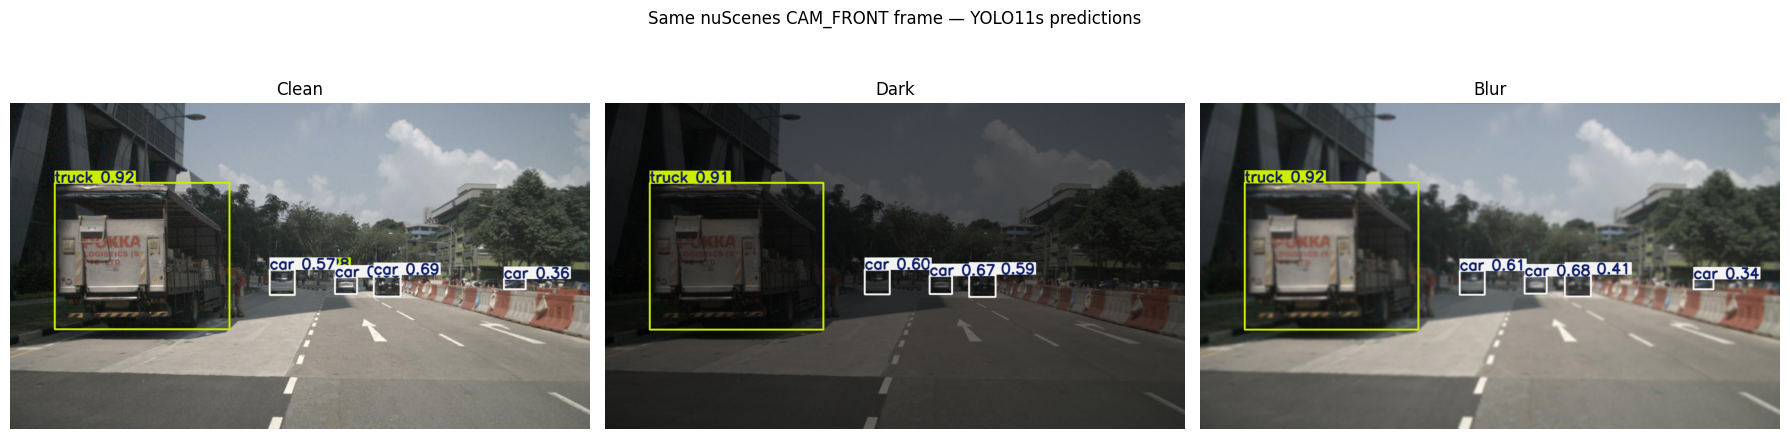

Saved comparison: /content/drive/MyDrive/ColabNotebooks/CMPE249_PROJ/results/yolo11/checkpoint_v1/clean_dark_blur_comparison.jpg


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, condition in zip(axes, CONDITIONS):
    ax.imshow(cv2.cvtColor(example_images[condition], cv2.COLOR_BGR2RGB))
    ax.set_title(condition.title())
    ax.axis("off")
plt.suptitle("Same nuScenes CAM_FRONT frame — YOLO11s predictions")
plt.tight_layout()
comparison_path = os.path.join(CHECKPOINT_DIR, "clean_dark_blur_comparison.jpg")
fig.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
for condition, annotated in example_images.items():
    cv2.imwrite(os.path.join(CHECKPOINT_DIR, f"{condition}.jpg"), annotated)
print("Saved comparison:", comparison_path)

## 5. Common 2D evaluation — IoU matching

**Milestone:** Implement and unit-test one-to-one class-aware matching. This provides per-image TP/FP/FN, precision, and recall at a specified IoU threshold; **it does not calculate mAP**. A dataset-wide confidence-ranked precision–recall evaluation is a later step.

In [20]:
def box_iou(a, b):
    """IoU of two pixel-space xyxy boxes."""
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0


def evaluate_image(predictions, ground_truth, threshold=0.5):
    """Greedy, confidence-ordered, one-to-one class-aware matching for ONE image."""
    matched_gt = set()
    tp = fp = 0
    for pred in sorted(predictions, key=lambda p: p['confidence'], reverse=True):
        candidates = [(box_iou(pred['box'], gt['box']), i)
                      for i, gt in enumerate(ground_truth)
                      if i not in matched_gt and pred['class'] == gt['class']]
        best_iou, best_idx = max(candidates, default=(0.0, None))
        if best_idx is not None and best_iou >= threshold:
            matched_gt.add(best_idx)
            tp += 1
        else:
            fp += 1
    fn = len(ground_truth) - len(matched_gt)
    return {'TP': tp, 'FP': fp, 'FN': fn,
            'precision': tp / (tp+fp) if tp+fp else 0.0,
            'recall': tp / (tp+fn) if tp+fn else 0.0}


In [21]:
# Synthetic unit tests: these require no nuScenes data.
gt_test = [{'class': 'car', 'box': [100,100,200,200]},
           {'class': 'truck', 'box': [300,100,500,300]}]
pred_test = [{'class': 'car', 'box': [105,105,195,195], 'confidence': 0.95},
             {'class': 'truck', 'box': [310,110,490,290], 'confidence': 0.90},
             {'class': 'car', 'box': [600,100,700,200], 'confidence': 0.40}]
assert box_iou([0,0,10,10], [0,0,10,10]) == 1.0
assert box_iou([0,0,10,10], [20,20,30,30]) == 0.0
assert evaluate_image(pred_test, gt_test) == {
    'TP': 2, 'FP': 1, 'FN': 0, 'precision': 2/3, 'recall': 1.0}
# Duplicate detections may match the same GT only once.
assert evaluate_image([pred_test[0], pred_test[0]], [gt_test[0]])['FP'] == 1
print('IoU and one-to-one matching tests passed.')
print('Synthetic example:', evaluate_image(pred_test, gt_test))

IoU and one-to-one matching tests passed.
Synthetic example: {'TP': 2, 'FP': 1, 'FN': 0, 'precision': 0.6666666666666666, 'recall': 1.0}


## 6. nuScenes ground-truth 3D → 2D projection prototype

The nuScenes devkit returns annotated 3D boxes transformed into the camera coordinate frame via `get_sample_data`. We project their corners through the camera intrinsic matrix and take the enclosing 2D rectangle. For this **initial prototype**, boxes with any corner behind the camera are excluded; rectangles are clipped to image bounds. This is a conservative approximation: occlusion, truncation, visibility, and class harmonization need a shared team policy before reporting formal cross-modality accuracy.

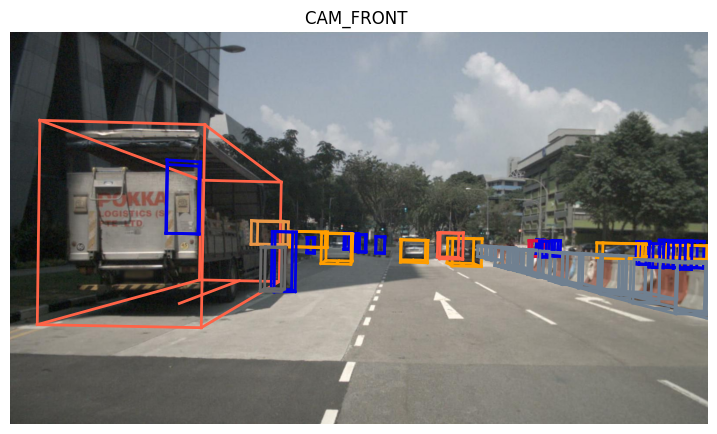

Camera image size: 1600 900
3D camera-frame annotation boxes returned: 48


In [22]:
from nuscenes.utils.geometry_utils import view_points
from PIL import Image

example_sample = samples[0]
example_cam_token = example_sample['data']['CAM_FRONT']
cam_path, camera_boxes, camera_intrinsic = nusc.get_sample_data(example_cam_token)
with Image.open(cam_path) as im:
    img_width, img_height = im.size

# Display nuScenes' own ground-truth camera projection as a visual sanity check.
nusc.render_sample_data(example_cam_token, with_anns=True)
plt.show()
print('Camera image size:', img_width, img_height)
print('3D camera-frame annotation boxes returned:', len(camera_boxes))


Projected common-class ground-truth boxes: 27


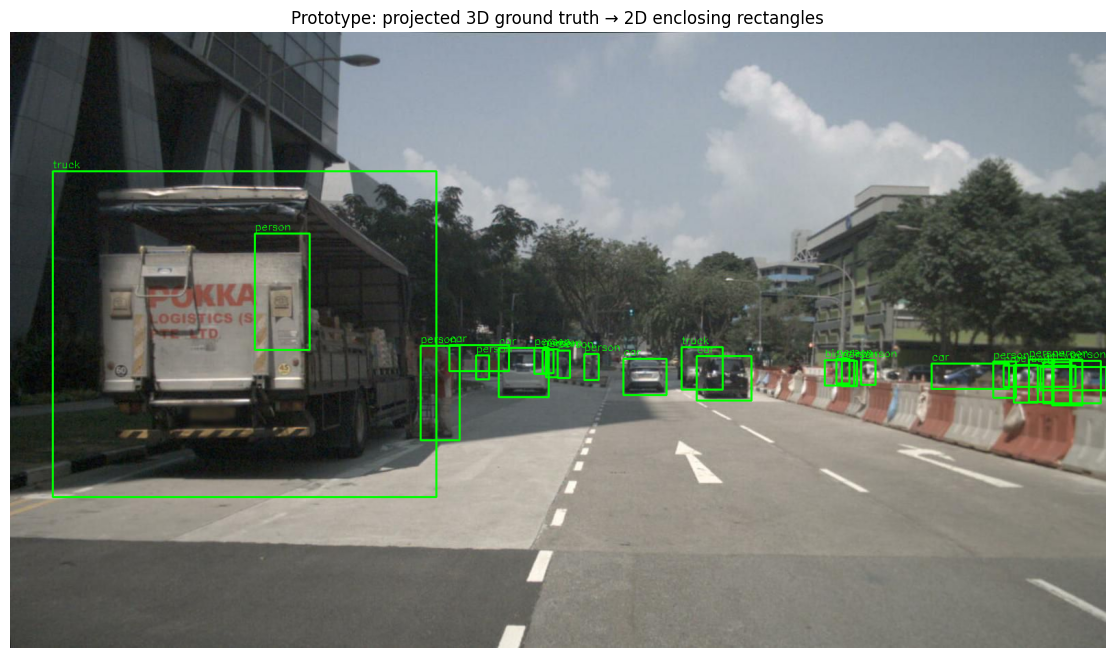

Saved: /content/drive/MyDrive/ColabNotebooks/CMPE249_PROJ/results/yolo11/checkpoint_v1/projected_gt_cam_front.jpg


In [23]:
# Preliminary class mapping. Classes not mapped here are excluded from this prototype.
NUSC_TO_COMMON = {
    'vehicle.car': 'car',
    'vehicle.truck': 'truck',
    'vehicle.bus.rigid': 'bus',
    'vehicle.bus.bendy': 'bus',
    'human.pedestrian.adult': 'person',
    'human.pedestrian.child': 'person',
    'human.pedestrian.construction_worker': 'person',
    'human.pedestrian.police_officer': 'person',
    'vehicle.bicycle': 'bicycle',
    'vehicle.motorcycle': 'motorcycle',
}

def projected_gt_for_camera(camera_token):
    path, boxes, intrinsic = nusc.get_sample_data(camera_token)
    with Image.open(path) as im:
        width, height = im.size
    gt_rows = []
    for box in boxes:
        common_class = NUSC_TO_COMMON.get(box.name)
        if common_class is None:
            continue
        corners = box.corners()  # 3 x 8, camera coordinates
        if np.any(corners[2, :] <= 0.1):
            continue  # conservative: skip near-plane crossings
        uv = view_points(corners, np.asarray(intrinsic), normalize=True)[:2]
        x1, y1 = np.min(uv, axis=1)
        x2, y2 = np.max(uv, axis=1)
        x1, x2 = np.clip([x1, x2], 0, width)
        y1, y2 = np.clip([y1, y2], 0, height)
        if x2 <= x1 or y2 <= y1:
            continue
        gt_rows.append({'class': common_class, 'box': [float(x1), float(y1), float(x2), float(y2)]})
    return gt_rows

example_gt = projected_gt_for_camera(example_cam_token)
print('Projected common-class ground-truth boxes:', len(example_gt))

image_bgr = cv2.imread(cam_path)
preview = image_bgr.copy()
for gt in example_gt:
    x1, y1, x2, y2 = map(int, gt['box'])
    cv2.rectangle(preview, (x1,y1), (x2,y2), (0,255,0), 2)
    cv2.putText(preview, gt['class'], (x1,max(12,y1-5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 1)
projection_path = os.path.join(CHECKPOINT_DIR, 'projected_gt_cam_front.jpg')
cv2.imwrite(projection_path, preview)
plt.figure(figsize=(15,8))
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.title('Prototype: projected 3D ground truth → 2D enclosing rectangles')
plt.axis('off')
plt.show()
print('Saved:', projection_path)

### 6.1 Preliminary clean-image matching sanity check

Match the already-exported YOLO clean predictions to the projected boxes for **one image**. These figures are *diagnostic only*, not final precision/recall or mAP: the projection currently excludes some boxes and does not model occlusion or full visibility policy.

In [24]:
token = example_sample['token']
example_preds = []
for _, r in pred_df[(pred_df['sample_token'] == token) &
                    (pred_df['condition'] == 'clean')].iterrows():
    example_preds.append({
        'class': r['class_name_coco'],
        'box': [float(r[k]) for k in ('x1','y1','x2','y2')],
        'confidence': float(r['confidence'])
    })
example_match = evaluate_image(example_preds, example_gt, threshold=0.5)
print('Prototype one-image IoU@0.50:', example_match)
print('WARNING: diagnostic only — projection and class policy not finalized.')

Prototype one-image IoU@0.50: {'TP': 4, 'FP': 2, 'FN': 23, 'precision': 0.6666666666666666, 'recall': 0.14814814814814814}


## 7. Shared team interface and next steps

**Artifacts for tomorrow:** `predictions.csv`, `per_image_results.csv`, `condition_summary.csv`, `clean_dark_blur_comparison.jpg`, `projected_gt_cam_front.jpg`, plus tested IoU matching code.

**Agreements needed:** (1) identical sample tokens and camera channels; (2) common class mapping (e.g., trailer and traffic lights are not shared COCO/nuScenes classes); (3) projection handling of occlusion, near-plane intersections, truncation, and visibility; (4) IoU and confidence thresholds; (5) standardized prediction schema and timestamps; (6) whether to report matched 2D metrics separately from native 3D mAP/NDS.

**Next implementation milestone:** dataset-wide 2D precision–recall curves and mAP after validating the ground-truth projection and filtering policy; then ROS 2 camera node and matched camera corruptions for fusion. DINO feature probing is secondary.

**Status:** Existing YOLO experiment has been run previously; **new cells in sections 5–6 have not been executed in this edited notebook** and must be verified in Colab before reporting results.